#### Requirements

In [12]:
import pandas as pd
import numpy as np

import sys
sys.path.append("../..")

from src.backtester import calculate_return, backtester
from src.strategies import run_momentum_strategy
from src.summary import summary

In [13]:
df = pd.read_csv("../../data/spy_daily.csv")
prices = df["Adj Close"]
returns = calculate_return(prices)
lookback = 252

In [14]:
momentum_df, momentum_results = run_momentum_strategy(prices, returns, lookback, 0.001)

In [15]:
time_invested = momentum_results["time_invested"]

#### Exposure Matched Random Strategies

In [16]:
def generate_random_signal_v2(prices, lookback):

    random_signal = [np.nan] * lookback

    choice = np.random.choice([0,1], size = len(prices) - lookback, p = [1 - time_invested,time_invested])

    random_signal = random_signal + choice.tolist()

    return random_signal

In [17]:
df["Random Signal"] = generate_random_signal_v2(prices, lookback)
random_signal = df["Random Signal"]

random_df, random_result = backtester(returns, random_signal, 0.001)
pd.Series(random_result)

total_return           -0.557731
cagr                   -0.031324
annual_volatility       0.167467
annual_sharpe          -0.106260
max_drawdown           -0.693890
calmar                 -0.045143
time_invested           0.768421
trades               2289.000000
dtype: float64

In [18]:
def run_simulation_v2(n):

    simulation_result = []

    for i in range(n):

        random_signal = generate_random_signal_v2(prices, lookback)
        _, random_result = backtester(returns, random_signal, 0.001)

        simulation_result.append(random_result)

    return simulation_result



In [19]:
np.random.seed(44)

simulation_output = run_simulation_v2(1000)
simulation_df = pd.DataFrame(simulation_output)
simulation_df

,total_return,cagr,annual_volatility,annual_sharpe,max_drawdown,calmar,time_invested,trades
0,-0.575245,-0.032850,0.165722,-0.118693,-0.704884,-0.046603,0.775387,2261
1,-0.597904,-0.034916,0.170442,-0.123208,-0.682150,-0.051185,0.778483,2250
2,-0.535162,-0.029442,0.164602,-0.099071,-0.752120,-0.039145,0.771672,2311
3,-0.361064,-0.017322,0.165845,-0.022277,-0.705379,-0.024558,0.772755,2289
4,-0.314679,-0.014632,0.167466,-0.004329,-0.701865,-0.020848,0.769350,2326
...,...,...,...,...,...,...,...,...
995,-0.051457,-0.002059,0.163427,0.069182,-0.563661,-0.003652,0.779721,2217
996,-0.454998,-0.023399,0.167470,-0.057386,-0.665606,-0.035155,0.773529,2231
997,-0.535703,-0.029486,0.168059,-0.093995,-0.802157,-0.036758,0.778328,2297
998,-0.398993,-0.019666,0.163106,-0.040276,-0.668812,-0.029404,0.776006,2305


Sharpe Average: -0.0376
Sharpe Median:  -0.0376
Largest Sharpe: 0.2249
Average No. of Trades: 2252.1200
Average Time Invested: 0.7752
Empirical p-value: 0.001


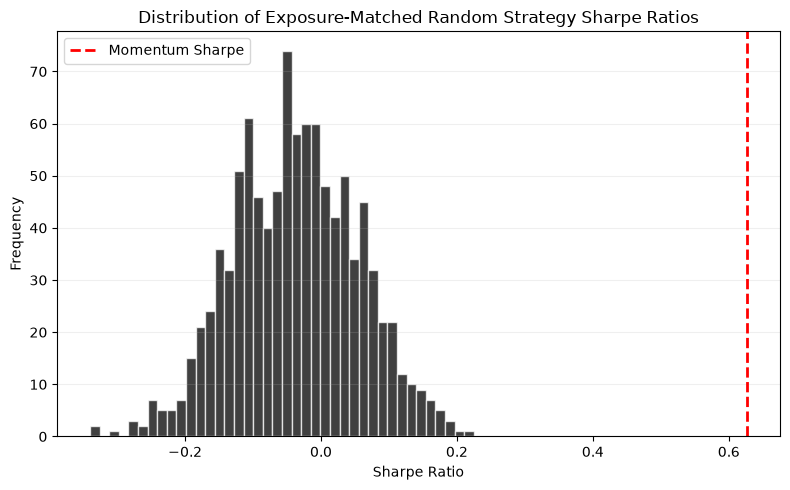

In [20]:
summary(simulation_df, momentum_results, "Distribution of Exposure-Matched Random Strategy Sharpe Ratios")